# Exploratory inspection of the exported prediction table

This notebook records the early numerical exploration. It is retained to make the investigation traceable; the [reviewed report](reports/FINAL_ANALYSIS.md) and [target-aware notebook](damp_secondary_analysis.ipynb) supply the better-matched comparisons used for interpretation.

**How to read its summaries.** The code below sometimes averages APEX outputs across organisms/versions or DeepAMP outputs across different training targets. Such family means and their spread are mathematical summaries of heterogeneous predictions, not repeated estimates of one shared MIC. The paper-reported DeepAMP heads use E. coli/B. subtilis measurements, and artificial inactive labels can influence large outputs. Declared µM units do not make these targets interchangeable.

New rationale cells explain why each step was inspected and where its interpretation stops. Original code cells, execution counts, and saved outputs are preserved; their presence is not a new endorsement of pooled biological comparisons. Metric units, denominators, and accuracy limits are stated before the relevant calculations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("df_damp_195625x57.tsv", sep="\t")
df

,Unnamed: 0,sequence,apex_1_0_E._coli_ATCC11775,apex_1_0_P._aeruginosa_PAO1,apex_1_0_P._aeruginosa_PA14,apex_1_0_S._aureus_ATCC12600,apex_1_0_E._coli_AIG221,apex_1_0_E._coli_AIG222,apex_1_0_K._pneumoniae_ATCC13883,apex_1_0_A._baumannii_ATCC19606,...,ai4amp_general_AMP,amp_clip_general_AMP,amp_read_unspecified_target,amplify_general_AMP,mbc_attention_E._coli_unspecified_strain,deep_amp_cnn_neg_Gram-negative_unspecified_species_and_strain,deep_amp_cnn_pos_Gram-positive_unspecified_species_and_strain,deep_amp_lstm_neg_Gram-negative_unspecified_species_and_strain,deep_amp_lstm_pos_Gram-positive_unspecified_species_and_strain,ampredictor_E._coli_unspecified_strain
0,0,GIKIPCGESCAWVDFCFTSIVGCSCENKVCYKN,140.090729,139.520859,139.791595,137.798248,143.334625,141.171600,140.390701,141.313828,...,0.513142,0.0,1.077,0.999625,65.892120,3279.440430,7708.883789,10164.394531,9281.424805,22.392818
1,1,TCHCRRSCYSTEYSYGTCTVMGINHRFCCL,132.153381,137.214630,139.669220,134.899475,136.206116,133.839615,135.777374,129.728073,...,0.836969,0.0,2.084,0.985475,14.442503,9670.003906,21.571730,0.213590,379.747131,9.990762
2,2,SATCCNYPPCYETYPESCL,139.628723,139.640854,139.788101,138.029251,140.463226,141.293076,140.423492,140.517029,...,0.104796,1.0,1.684,0.000387,27.809435,10549.166016,9735.451172,9666.691406,9637.945312,6.652004
3,3,AANAKLFDVRQSCCSAPLCALLYRVMCG,134.795547,134.168747,130.230072,133.302124,135.274307,137.303604,137.226288,136.947144,...,0.969110,0.0,3.408,0.021094,48.337688,9998.182617,9906.286133,10113.919922,9872.126953,18.326488
4,4,TPPAGPDGGPP,137.431976,137.827225,134.804153,139.300995,138.079102,138.868439,137.844238,138.407913,...,0.091469,0.0,3.399,0.020897,92.933578,10592.178711,10294.554688,10134.317383,9508.123047,29.168108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195620,190968,MTKKNLKPQQAAPVQREINTTSSESGTSTGLTPHQAYLGIPLPFAG...,127.715225,128.709000,125.381432,131.741837,127.786705,129.616394,129.458405,131.788818,...,0.024187,0.0,2.915,0.000083,27.668364,NaN,NaN,NaN,NaN,101.325935
195621,190969,ARLHRPSEFARLGLVIAKRFAARAVTRNTLKRVIRELDYVVLKRSA...,61.237080,63.598183,55.067059,93.003784,65.778542,68.044693,89.352036,42.468468,...,0.981177,0.0,1.887,0.669382,2.135286,NaN,NaN,NaN,NaN,16.657660
195622,190970,DKFSTNEEFSKIAVVASKKVGKAVVRNRSKRILRALQKYIFLEKNL...,66.021729,55.303123,55.003826,72.332932,64.024857,63.338104,88.194603,58.389038,...,0.989859,0.0,1.445,0.992500,0.697206,NaN,NaN,NaN,NaN,8.824920
195623,190971,DSLKNKSEFDKLGLSVSKKVGNAVKRNLIKRRLRSCQALVFLEKHF...,79.272888,79.446838,76.913567,108.274925,72.002167,76.524345,96.829994,76.560669,...,0.988334,0.0,1.408,0.986610,8.270863,NaN,NaN,NaN,NaN,12.223533


In [3]:
df.columns

Index(['Unnamed: 0', 'sequence', 'apex_1_0_E._coli_ATCC11775',
       'apex_1_0_P._aeruginosa_PAO1', 'apex_1_0_P._aeruginosa_PA14',
       'apex_1_0_S._aureus_ATCC12600', 'apex_1_0_E._coli_AIG221',
       'apex_1_0_E._coli_AIG222', 'apex_1_0_K._pneumoniae_ATCC13883',
       'apex_1_0_A._baumannii_ATCC19606',
       'apex_1_0_A._muciniphila_ATCC_BAA-835',
       'apex_1_0_B._fragilis_ATCC25285', 'apex_1_0_B._vulgatus_ATCC8482',
       'apex_1_0_C._aerofaciens_ATCC25986', 'apex_1_0_C._scindens_ATCC35704',
       'apex_1_0_B._thetaiotaomicron_ATCC29148',
       'apex_1_0_B._thetaiotaomicron_Complemmented',
       'apex_1_0_B._thetaiotaomicron_Mutant', 'apex_1_0_B._uniformis_ATCC8492',
       'apex_1_0_B._eggerthi_ATCC27754', 'apex_1_0_C._spiroforme_ATCC29900',
       'apex_1_0_P._distasonis_ATCC8503', 'apex_1_0_P._copri_DSMZ18205',
       'apex_1_0_B._ovatus_ATCC8483', 'apex_1_0_E._rectale_ATCC33656',
       'apex_1_0_C._symbiosum', 'apex_1_0_R._obeum', 'apex_1_0_R._torques',
       'apex

**Rationale — identify the output groups before summarizing.** Explicit column lists make it possible to see which outputs a family average would combine. The 45 APEX columns mix strain targets and versions; the four DeepAMP columns mix fitted CNN/LSTM variants and two paper-reported training species. The two remaining regressors concern broader E. coli measurements. These groups are useful for inventory, not proof that their averages share one biological interpretation.

In [4]:
apex_cols  = ['apex_1_0_E._coli_ATCC11775',
       'apex_1_0_P._aeruginosa_PAO1', 'apex_1_0_P._aeruginosa_PA14',
       'apex_1_0_S._aureus_ATCC12600', 'apex_1_0_E._coli_AIG221',
       'apex_1_0_E._coli_AIG222', 'apex_1_0_K._pneumoniae_ATCC13883',
       'apex_1_0_A._baumannii_ATCC19606',
       'apex_1_0_A._muciniphila_ATCC_BAA-835',
       'apex_1_0_B._fragilis_ATCC25285', 'apex_1_0_B._vulgatus_ATCC8482',
       'apex_1_0_C._aerofaciens_ATCC25986', 'apex_1_0_C._scindens_ATCC35704',
       'apex_1_0_B._thetaiotaomicron_ATCC29148',
       'apex_1_0_B._thetaiotaomicron_Complemmented',
       'apex_1_0_B._thetaiotaomicron_Mutant', 'apex_1_0_B._uniformis_ATCC8492',
       'apex_1_0_B._eggerthi_ATCC27754', 'apex_1_0_C._spiroforme_ATCC29900',
       'apex_1_0_P._distasonis_ATCC8503', 'apex_1_0_P._copri_DSMZ18205',
       'apex_1_0_B._ovatus_ATCC8483', 'apex_1_0_E._rectale_ATCC33656',
       'apex_1_0_C._symbiosum', 'apex_1_0_R._obeum', 'apex_1_0_R._torques',
       'apex_1_0_S._aureus_(ATCC_BAA-1556)_-_MRSA',
       'apex_1_0_vancomycin-resistant_E._faecalis_ATCC700802',
       'apex_1_0_vancomycin-resistant_E._faecium_ATCC700221',
       'apex_1_0_E._coli_Nissle',
       'apex_1_0_Salmonella_enterica_ATCC_9150_(BEIRES_NR-515)',
       'apex_1_0_Salmonella_enterica_(BEIRES_NR-170)',
       'apex_1_0_Salmonella_enterica_ATCC_9150_(BEIRES_NR-174)',
       'apex_1_0_L._monocytogenes_ATCC_19111_(BEIRES_NR-106)',
       'apex_1_1_A._baumannii_ATCC_19606', 'apex_1_1_E._coli_ATCC_11775',
       'apex_1_1_E._coli_AIC221', 'apex_1_1_E._coli_AIC222',
       'apex_1_1_K._pneumoniae_ATCC_13883', 'apex_1_1_P._aeruginosa_PA01',
       'apex_1_1_P._aeruginosa_PA14', 'apex_1_1_S._aureus_ATCC_12600',
       'apex_1_1_S._aureus_(ATCC_BAA-1556)_-_MRSA',
       'apex_1_1_vancomycin-resistant_E._faecalis_ATCC_700802',
       'apex_1_1_vancomycin-resistant_E._faecium_ATCC_700221']

deepamp_cols = ['deep_amp_cnn_neg_Gram-negative_unspecified_species_and_strain',
       'deep_amp_cnn_pos_Gram-positive_unspecified_species_and_strain',
       'deep_amp_lstm_neg_Gram-negative_unspecified_species_and_strain',
       'deep_amp_lstm_pos_Gram-positive_unspecified_species_and_strain',]

other_reg_cols = ['mbc_attention_E._coli_unspecified_strain','ampredictor_E._coli_unspecified_strain']
regression_mic_cols = ["sequence"] +  apex_cols +  deepamp_cols  + other_reg_cols
# ANIA, EvoGradient Predictors, SenseXAMP, AMPActiPred, BERTMIC all missing (from README of github)


df_mic_reg = df.loc[:, regression_mic_cols]

In [5]:
df_mic_reg

,sequence,apex_1_0_E._coli_ATCC11775,apex_1_0_P._aeruginosa_PAO1,apex_1_0_P._aeruginosa_PA14,apex_1_0_S._aureus_ATCC12600,apex_1_0_E._coli_AIG221,apex_1_0_E._coli_AIG222,apex_1_0_K._pneumoniae_ATCC13883,apex_1_0_A._baumannii_ATCC19606,apex_1_0_A._muciniphila_ATCC_BAA-835,...,apex_1_1_S._aureus_ATCC_12600,apex_1_1_S._aureus_(ATCC_BAA-1556)_-_MRSA,apex_1_1_vancomycin-resistant_E._faecalis_ATCC_700802,apex_1_1_vancomycin-resistant_E._faecium_ATCC_700221,deep_amp_cnn_neg_Gram-negative_unspecified_species_and_strain,deep_amp_cnn_pos_Gram-positive_unspecified_species_and_strain,deep_amp_lstm_neg_Gram-negative_unspecified_species_and_strain,deep_amp_lstm_pos_Gram-positive_unspecified_species_and_strain,mbc_attention_E._coli_unspecified_strain,ampredictor_E._coli_unspecified_strain
0,GIKIPCGESCAWVDFCFTSIVGCSCENKVCYKN,140.090729,139.520859,139.791595,137.798248,143.334625,141.171600,140.390701,141.313828,133.574677,...,513.057678,512.523376,514.927612,502.069122,3279.440430,7708.883789,10164.394531,9281.424805,65.892120,22.392818
1,TCHCRRSCYSTEYSYGTCTVMGINHRFCCL,132.153381,137.214630,139.669220,134.899475,136.206116,133.839615,135.777374,129.728073,140.555511,...,467.284241,510.900665,494.762146,457.751953,9670.003906,21.571730,0.213590,379.747131,14.442503,9.990762
2,SATCCNYPPCYETYPESCL,139.628723,139.640854,139.788101,138.029251,140.463226,141.293076,140.423492,140.517029,142.061005,...,506.185516,510.609497,509.924347,498.431458,10549.166016,9735.451172,9666.691406,9637.945312,27.809435,6.652004
3,AANAKLFDVRQSCCSAPLCALLYRVMCG,134.795547,134.168747,130.230072,133.302124,135.274307,137.303604,137.226288,136.947144,136.006317,...,504.361023,512.575195,502.255463,494.803406,9998.182617,9906.286133,10113.919922,9872.126953,48.337688,18.326488
4,TPPAGPDGGPP,137.431976,137.827225,134.804153,139.300995,138.079102,138.868439,137.844238,138.407913,119.860596,...,495.591034,509.065979,490.850525,505.409332,10592.178711,10294.554688,10134.317383,9508.123047,92.933578,29.168108
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195620,MTKKNLKPQQAAPVQREINTTSSESGTSTGLTPHQAYLGIPLPFAG...,127.715225,128.709000,125.381432,131.741837,127.786705,129.616394,129.458405,131.788818,123.190430,...,473.865570,487.796021,444.553894,494.943542,NaN,NaN,NaN,NaN,27.668364,101.325935
195621,ARLHRPSEFARLGLVIAKRFAARAVTRNTLKRVIRELDYVVLKRSA...,61.237080,63.598183,55.067059,93.003784,65.778542,68.044693,89.352036,42.468468,43.706810,...,219.402832,342.397583,363.657043,105.788872,NaN,NaN,NaN,NaN,2.135286,16.657660
195622,DKFSTNEEFSKIAVVASKKVGKAVVRNRSKRILRALQKYIFLEKNL...,66.021729,55.303123,55.003826,72.332932,64.024857,63.338104,88.194603,58.389038,38.373753,...,212.527130,253.510376,412.119263,105.725189,NaN,NaN,NaN,NaN,0.697206,8.824920
195623,DSLKNKSEFDKLGLSVSKKVGNAVKRNLIKRRLRSCQALVFLEKHF...,79.272888,79.446838,76.913567,108.274925,72.002167,76.524345,96.829994,76.560669,49.445347,...,308.843018,382.371613,413.755035,318.299164,NaN,NaN,NaN,NaN,8.270863,12.223533


### APEX variation for each sequence

`df_apex_stats` stores the arithmetic mean, sample SD (`ddof=1`), and number of available APEX predictions per sequence. `average_apex_sd` is the unweighted average of these per-sequence SDs, rather than the SD of all pooled predictions. APEX columns span organisms, strains, and model versions, so this describes variation across those outputs.

**Rationale — inspect within-row output variation.** APEX sample SD measures dispersion around a peptide's mean across the selected APEX outputs, using the number of available outputs minus one in the variance denominator. Those outputs differ by target and version, so this is not technical repeatability or an uncertainty estimate. Averaging per-peptide SDs gives each peptide one contribution, rather than pooling all outputs into one SD.

In [6]:
df_apex = df_mic_reg.set_index("sequence")[apex_cols].copy()
df_apex_stats = pd.DataFrame({
    "apex_mean": df_apex.mean(axis=1),
    "apex_std": df_apex.std(axis=1, ddof=1),
    "apex_n_predictions": df_apex.count(axis=1),
})
average_apex_sd = df_apex_stats["apex_std"].mean()
print(f"Average per-sequence APEX SD: {average_apex_sd:.6f}")
display(df_apex_stats.head())

Average per-sequence APEX SD: 252.313092


,apex_mean,apex_std,apex_n_predictions
sequence,,,
GIKIPCGESCAWVDFCFTSIVGCSCENKVCYKN,334.418917,421.414771,45
TCHCRRSCYSTEYSYGTCTVMGINHRFCCL,319.225186,403.353103,45
SATCCNYPPCYETYPESCL,328.470529,408.471337,45
AANAKLFDVRQSCCSAPLCALLYRVMCG,335.771762,446.348652,45
TPPAGPDGGPP,332.059461,422.669253,45


**Rationale — inspect an individual extreme profile.** Displaying one sequence's full output vector helps identify whether a large spread comes from a few heads or a broad change across targets. This sequence is an illustrative inspection, not a random sample or validated biological counterexample. Its individual values need their output-target labels and must not be read as interchangeable replicate MIC measurements.

In [34]:
df_apex.loc["GIKIPCGESCAWVDFCFTSIVGCSCENKVCYKN", :]

apex_1_0_E._coli_ATCC11775                                 140.090729
apex_1_0_P._aeruginosa_PAO1                                139.520859
apex_1_0_P._aeruginosa_PA14                                139.791595
apex_1_0_S._aureus_ATCC12600                               137.798248
apex_1_0_E._coli_AIG221                                    143.334625
apex_1_0_E._coli_AIG222                                    141.171600
apex_1_0_K._pneumoniae_ATCC13883                           140.390701
apex_1_0_A._baumannii_ATCC19606                            141.313828
apex_1_0_A._muciniphila_ATCC_BAA-835                       133.574677
apex_1_0_B._fragilis_ATCC25285                             139.179871
apex_1_0_B._vulgatus_ATCC8482                              135.900223
apex_1_0_C._aerofaciens_ATCC25986                          138.708847
apex_1_0_C._scindens_ATCC35704                             130.030197
apex_1_0_B._thetaiotaomicron_ATCC29148                     139.112335
apex_1_0_B._thetaiot

**Rationale — make the largest numerical spreads visible.** Ranking by SD highlights rows that deserve inspection, but the plot is selected for extremes and cannot describe the whole population. The bar length is the sample SD across heterogeneous APEX outputs in exported concentration units. Large values can reflect different targets, label handling, and extrapolation; they do not identify unreliable peptides or measured resistance.

,apex_mean,apex_std,apex_n_predictions
sequence,,,
YRMWRWRWRWR,329.009527,606.322597,45
RWWRRWRRWWR,341.113551,602.026438,45
RRWQWWWQWRR,330.240224,581.244916,45
WRLWIWWIR,232.892488,580.515843,45
WRWRWRWRWR,346.810675,579.823306,45
WWRMLRQVLRR,267.758542,578.332608,45
FYKLRLILWWR,217.191841,575.277457,45
RWLWRQRIRLY,209.113772,571.558273,45
KLVFLPLRLVWK,228.622774,566.967088,45


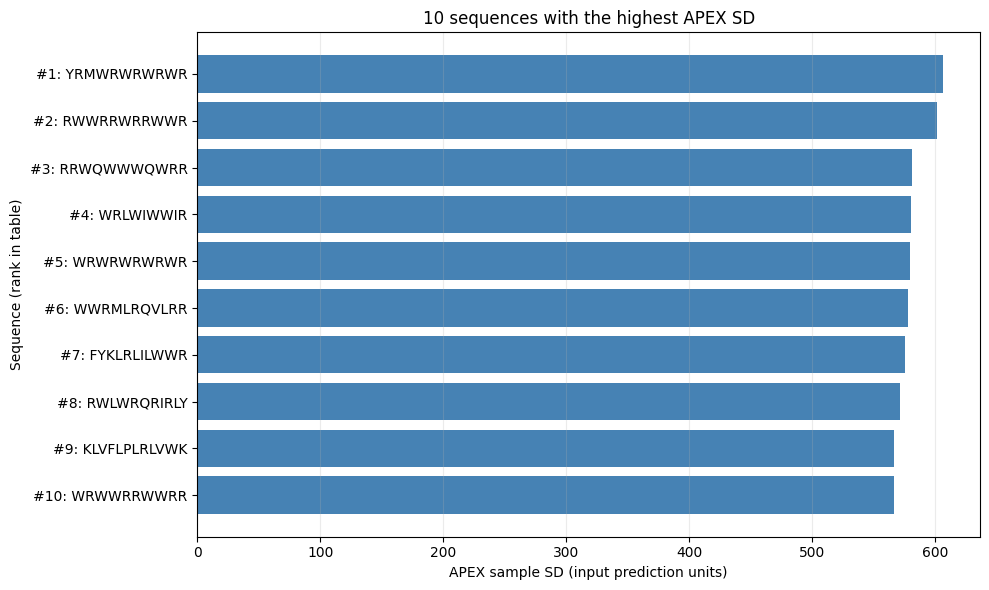

In [7]:
top10_apex_sd = df_apex_stats.nlargest(10, "apex_std").copy()
display(top10_apex_sd)

# Keep the full sequences in the table; shortened plot labels stay readable.
plot_data = top10_apex_sd.iloc[::-1]
labels = [f"#{rank}: {seq[:18]}{'…' if len(seq) > 18 else ''}"
          for rank, seq in zip(range(len(top10_apex_sd), 0, -1), plot_data.index)]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(labels, plot_data["apex_std"], color="steelblue")
ax.set(xlabel="APEX sample SD (input prediction units)", ylabel="Sequence (rank in table)",
       title="10 sequences with the highest APEX SD")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

### Collapse model families and compare predictions

`df_mic_collapsed` contains an arithmetic mean of the 45 APEX outputs, a mean of the four DeepAMP outputs, and the two other prediction columns. Means skip missing values; `df_family_counts` records their contribution counts. Original columns remain available in `df_mic_reg`.

The reviewed adapters support exported µM units for these columns, but they do not establish a common biological target. APEX mixes organisms and versions, while DeepAMP mixes architectures and the E. coli/B. subtilis training heads. The resulting disagreement combines target coverage, transformations, and fitted-model differences. These pooled means are historical EDA summaries; the reviewed report uses selected shared targets instead.


**Rationale — expose the effect of giving each family one numerical contribution.** Collapsing many outputs prevents a family with more columns from dominating a raw comparison simply through column count. However, averaging different targets does not create a matched endpoint. These family means are retained as exploratory arithmetic and are not the basis for claims about comparative model accuracy. Contribution counts also matter because missing outputs can change which heads form a mean.

In [8]:
df_predictions = df_mic_reg.set_index("sequence")
df_mic_collapsed = pd.DataFrame({
    "apex": df_apex_stats["apex_mean"],
    "deepamp": df_predictions[deepamp_cols].mean(axis=1),
    **{col: df_predictions[col] for col in other_reg_cols},
})
df_family_counts = pd.DataFrame({
    "apex_n_predictions": df_apex_stats["apex_n_predictions"],
    "deepamp_n_predictions": df_predictions[deepamp_cols].count(axis=1),
})
print(f"Collapsed predictions: {df_mic_collapsed.shape[0]:,} sequences × "
      f"{df_mic_collapsed.shape[1]} predictors")
display(df_mic_collapsed.head())
display(df_mic_collapsed.isna().sum().rename("missing_sequences").to_frame())
display(df_family_counts.value_counts().rename("n_sequences").to_frame())

Collapsed predictions: 195,625 sequences × 4 predictors


,apex,deepamp,mbc_attention_E._coli_unspecified_strain,ampredictor_E._coli_unspecified_strain
sequence,,,,
GIKIPCGESCAWVDFCFTSIVGCSCENKVCYKN,334.418917,7608.535889,65.892120,22.392818
TCHCRRSCYSTEYSYGTCTVMGINHRFCCL,319.225186,2517.884089,14.442503,9.990762
SATCCNYPPCYETYPESCL,328.470529,9897.313477,27.809435,6.652004
AANAKLFDVRQSCCSAPLCALLYRVMCG,335.771762,9972.628906,48.337688,18.326488
TPPAGPDGGPP,332.059461,10132.293457,92.933578,29.168108


,missing_sequences
apex,0
deepamp,4749
mbc_attention_E._coli_unspecified_strain,667
ampredictor_E._coli_unspecified_strain,11


n_sequences
apex_n_predictions deepamp_n_predictions             
45                 4                           190876
                   0                             4749

### Per-sequence disagreement measures

All measures use available predictors and require at least two. `n_models` and `n_positive_models` make the comparison coverage explicit; `complete_models` identifies rows with all four predictions.

- `sd`: sample SD across the collapsed predictors, in input units.
- `range`: largest minus smallest prediction, in input units.
- `median_absolute_deviation`: median absolute distance from the row median (unscaled), in input units; less sensitive to extremes.
- `mean_pairwise_abs_difference`: mean absolute difference over all available unordered predictor pairs, in input units.
- `cv`: SD divided by the absolute row mean, a dimensionless relative spread; undefined for a zero mean.
- `log2_sd`: sample SD of log2 predictions, describing multiplicative spread.
- `max_min_fold`: largest divided by smallest prediction (1 means agreement).

Log2 SD and fold range are reported only when **all available predictions are positive**. Higher values indicate greater disagreement, except the coverage fields. Summaries use each metric's valid rows; complete-case averages allow comparison on the same set of sequences.

**Rationale — compare different definitions of numerical spread.** SD, range, absolute deviations, and fold ratios emphasize different aspects of a row. Raw-unit measures grow with concentration; CV divides SD by the absolute row mean; logarithmic measures summarize multiplicative differences. A shared denominator/complete-case restriction is needed when comparing population averages. None of these metrics repairs the preceding mixture of biological targets.

In [9]:
from itertools import combinations

values = df_mic_collapsed
n_models = values.count(axis=1)
row_mean = values.mean(axis=1)
row_median = values.median(axis=1)
row_sd = values.std(axis=1, ddof=1)
predictor_pairs = list(combinations(values.columns, 2))
pairwise_abs = pd.DataFrame({
    f"{left} vs {right}": (values[left] - values[right]).abs()
    for left, right in predictor_pairs
})
positive = values.where(values > 0)
all_available_positive = positive.count(axis=1).eq(n_models)
positive_rows = positive.where(all_available_positive, axis=0)

metrics = pd.DataFrame({
    "sd": row_sd,
    "range": values.max(axis=1) - values.min(axis=1),
    "median_absolute_deviation": values.sub(row_median, axis=0).abs().median(axis=1),
    "mean_pairwise_abs_difference": pairwise_abs.mean(axis=1),
    "cv": row_sd / row_mean.abs().replace(0, np.nan),
    "log2_sd": np.log2(positive_rows).std(axis=1, ddof=1),
    "max_min_fold": positive_rows.max(axis=1) / positive_rows.min(axis=1),
}).where(n_models.ge(2), axis=0)

df_disagreement = pd.DataFrame({
    "n_models": n_models,
    "n_positive_models": positive.count(axis=1),
    "complete_models": n_models.eq(values.shape[1]),
}).join(metrics)
average_disagreement_sd = df_disagreement["sd"].mean()
disagreement_summary = metrics.agg(["count", "mean", "median", "max"]).T
disagreement_summary["complete_case_mean"] = metrics.loc[
    df_disagreement["complete_models"]
].mean()
print(f"Average per-sequence SD across collapsed predictors: {average_disagreement_sd:.6f}")
display(disagreement_summary)
display(df_mic_collapsed.join(df_disagreement).nlargest(10, "sd"))

Average per-sequence SD across collapsed predictors: 1625.915961


,count,mean,median,max,complete_case_mean
sd,195625.0,1625.915961,129.584853,58377.895001,1657.960949
range,195625.0,3292.207080,267.057951,116795.462034,3360.895785
median_absolute_deviation,195625.0,67.017302,54.271567,2438.059177,68.070570
mean_pairwise_abs_difference,195625.0,1668.872411,147.454457,58417.551118,1699.658231
cv,195625.0,1.547112,1.671960,1.997233,1.547483
log2_sd,195625.0,3.118711,2.982235,8.138556,3.113170
max_min_fold,195625.0,859.118150,96.352800,251038.263912,880.135967


,apex,deepamp,mbc_attention_E._coli_unspecified_strain,ampredictor_E._coli_unspecified_strain,n_models,n_positive_models,complete_models,sd,range,median_absolute_deviation,mean_pairwise_abs_difference,cv,log2_sd,max_min_fold
sequence,,,,,,,,,,,,,,
ARKFKWGKLFSAAKKLYKKGKKLSKNKNFKKALKFGKQLAKNLQAGEE,119.770303,116796.183147,0.849697,0.721113,4,4,True,58377.895001,116795.462034,59.524595,58417.551118,1.997233,8.138556,161966.474940
ARKFKWGKLFSTAKKLYKKGKKLSKNKNFKKALKFGKQLAKNLQAGEE,118.118443,97969.919571,0.948592,0.661767,4,4,True,48965.036215,97969.257804,58.728338,49004.157210,1.996746,8.016150,148042.852808
ARKFKWGKLFSAAKKLYKKGKKLSKNKNFKKALKFGKQLAKNLQAG,111.468293,62795.568528,0.476360,0.788775,4,4,True,31379.038859,62795.092168,55.495966,31415.992671,1.995224,7.912722,131823.741784
ARKFKWGKLFSTAKKLYKKGKKLSKNKNFKKALKFGKQLAKNLQAG,109.833850,54715.159153,0.521737,0.774633,4,4,True,27339.106325,54714.637416,54.656057,27375.495244,1.994598,7.793703,104871.225942
ARKFKWGKLFSAAKKLYKKGKKLSKNKNFKKALKFGKQLAKNLQAGE,118.757525,54707.587936,0.593294,0.747916,4,4,True,27333.834196,54706.994642,59.082115,27373.165589,1.994163,7.764192,92209.927409
NHEIKKLSKEKVEMISKLKWGEALYRYRGKKKLMFNWYKLHPKKLAPT,128.282922,53465.872221,8.074762,2.889185,4,4,True,26709.791115,53462.983035,62.696868,26751.526211,1.993078,6.363107,18505.519273
ARKFKWGKLFSTAKKLYKKGKKLSKNKNFKKALKFGKQLAKNLQAGE,116.957478,49131.691813,0.606466,0.741895,4,4,True,24546.189475,49131.085347,58.175506,24584.911938,1.993599,7.688293,81013.158189
DRKIDFLKKLLKKFPLRAMRKINRLFERRRNRVKDFLHKLTIQLSRL,116.797266,38714.871512,3.304416,1.095190,4,4,True,19337.311757,38713.776322,57.851038,19375.803636,1.991686,6.803563,35349.923255
QKQFRLLKTAALVIQQRLRAWAAGRKQRMEYLELRHAVLTLQSAWRGR,155.985567,35021.944801,1.570282,1.143664,4,4,True,17484.674426,35020.801137,77.420952,17536.136450,1.987988,6.989609,30622.585285


### Pairwise disagreement across sequences

Each row uses sequences with both collapsed predictions. `n_sequences` is that pair's denominator. Mean signed difference is left minus right: positive means the left prediction is larger. MAE is the mean absolute difference; RMSE is the square root of the mean squared difference and gives large gaps more weight. These two metrics have the same units as the compared predictions. They describe prediction–prediction disagreement here, not error against laboratory observations.

Spearman correlation compares ranks from −1 (reversed ordering) to +1 (same ordering); a high value can coexist with a large numerical offset. On positive pairs, `mean_abs_log2_difference` averages the absolute log2(left/right) ratio. A value of 1 means an average one-step, twofold separation on the log scale; exponentiating it gives a geometric mean larger/smaller ratio, not an arithmetic mean fold gap. Different pairwise coverage and the collapsed target mixtures limit comparisons between rows.


**Rationale — distinguish agreement in ordering from agreement in numbers.** Two columns can preserve nearly the same ranks while differing by a constant factor. Spearman describes that ordering; signed difference, MAE, and RMSE describe numerical gaps. In this cell both columns are predictions, so MAE/RMSE are disagreement summaries, not experimental error scores. Large gaps can also arise from the unmatched family averages and should not be used to rank model accuracy.

In [10]:
pairwise_rows = []
for left, right in predictor_pairs:
    paired = values[[left, right]].dropna()
    difference = paired[left] - paired[right]
    positive_pairs = paired.loc[paired.gt(0).all(axis=1)]
    pairwise_rows.append({
        "left": left,
        "right": right,
        "n_sequences": len(paired),
        "mean_signed_difference": difference.mean(),
        "mae": difference.abs().mean(),
        "rmse": np.sqrt(difference.pow(2).mean()),
        "spearman_r": paired[left].rank().corr(paired[right].rank()),
        "n_positive_pairs": len(positive_pairs),
        "mean_abs_log2_difference": (
            np.log2(positive_pairs[left]) - np.log2(positive_pairs[right])
        ).abs().mean(),
    })
df_pairwise_disagreement = pd.DataFrame(pairwise_rows).sort_values("mae", ascending=False)
display(df_pairwise_disagreement)

,left,right,n_sequences,mean_signed_difference,mae,rmse,spearman_r,n_positive_pairs,mean_abs_log2_difference
4,deepamp,ampredictor_E._coli_unspecified_strain,190865,3298.726287,3302.795139,5307.232659,0.165681,190865,5.240926
3,deepamp,mbc_attention_E._coli_unspecified_strain,190209,3270.703399,3278.868468,5278.068508,0.282644,190209,4.781256
0,apex,deepamp,190876,-3119.275661,3244.403740,5163.878053,0.631689,190876,3.636006
2,apex,ampredictor_E._coli_unspecified_strain,195614,179.218816,180.773711,195.264930,0.306244,195614,4.271595
1,apex,mbc_attention_E._coli_unspecified_strain,194958,160.862931,176.117294,208.574416,0.409827,194958,3.717556
5,mbc_attention_E._coli_unspecified_strain,ampredictor_E._coli_unspecified_strain,194947,18.433260,31.802724,119.883309,0.529613,194947,1.526009
